# Proyek Analisis Data: Pola Permintaan Bike Sharing (2011–2012)

- **Nama:** Titania Latanza Shauvinna
- **Email:** shauvinnatitania@gmail.com
- **ID Dicoding:** titanialatanza

**Dataset:** [Bike Sharing Dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), Capital Bikeshare, Washington, D.C., periode 1 Januari 2011–31 Desember 2012. Data asli yang digunakan adalah `data/day.csv` (harian) dan `data/hour.csv` (per jam) dari arsip dataset yang disediakan Dicoding. Analisis deskriptif ini **tidak menyimpulkan hubungan sebab-akibat**.

## Menentukan Pertanyaan Bisnis

1. **Pertanyaan 1:** Selama **1 Januari 2011 hingga 31 Desember 2012**, bagaimana perbandingan **rata-rata penyewaan sepeda per hari** antara **hari kerja dan hari non-kerja pada setiap bulan kalender**, serta pada bulan apa **selisih absolut rata-ratanya** paling besar? Hasil ini digunakan untuk menyusun prioritas penyediaan armada antarjenis hari.
2. **Pertanyaan 2:** Selama **1 Januari 2011 hingga 31 Desember 2012**, **pada jam berapa** rata-rata penyewaan sepeda **per jam** mencapai puncak pada **hari kerja** dan **hari non-kerja**, serta berapa besar rata-rata tersebut? Hasil ini digunakan untuk merencanakan redistribusi sepeda menjelang jam sibuk.

Kedua pertanyaan mengikuti pendekatan **SMART**: spesifik pada permintaan layanan dan jenis hari; terukur melalui rata-rata, selisih, dan jam puncak; berorientasi tindakan operasional; relevan untuk pengelola layanan; dan dibatasi periode 2011–2012.

**Definisi:** Hari kerja (`workingday=1`) adalah hari yang bukan akhir pekan dan bukan hari libur. Hari non-kerja (`workingday=0`) termasuk akhir pekan maupun hari libur. *Jumlah penyewaan* adalah `cnt = casual + registered`, **bukan** jumlah pelanggan unik. Bulan kalender digabung lintas 2011 dan 2012 untuk membandingkan pola musiman rata-rata, bukan tren bulan-ke-bulan secara kronologis.

## Import Semua Packages/Library yang Digunakan

Gunakan `pandas` untuk penyiapan, agregasi, dan uji integritas; `numpy` untuk perhitungan dan batas binning; serta `matplotlib` untuk grafik. Semua proses menggunakan analisis deskriptif (tanpa *machine learning*).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

pd.set_option('display.float_format', lambda value: f'{value:,.2f}')
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10,
    'font.size': 10,
})
WARNA_KERJA = '#185ABD'
WARNA_NONKERJA = '#E07B39'
NAMA_BULAN = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

## Data Wrangling
### Gathering Data

Muat kedua file asli **secara terpisah** agar unit observasi tidak tercampur: `day.csv` mewakili **satu hari**, sedangkan `hour.csv` mewakili **satu jam pada tanggal tertentu**. Path bersifat relatif terhadap folder proyek, sehingga notebook perlu dijalankan dari folder yang berisi `data/` dan `dashboard/`.

In [2]:
folder_data = Path('data')
day_df = pd.read_csv(folder_data / 'day.csv')
hour_df = pd.read_csv(folder_data / 'hour.csv')

print(f'Data harian: {day_df.shape[0]:,} baris, {day_df.shape[1]} kolom')
print(f'Data per jam: {hour_df.shape[0]:,} baris, {hour_df.shape[1]} kolom')
print('Rentang tanggal:', day_df['dteday'].min(), 'hingga', day_df['dteday'].max())
display(day_df.head(3))
display(hour_df.head(3))

Data harian: 731 baris, 16 kolom
Data per jam: 17,379 baris, 17 kolom
Rentang tanggal: 2011-01-01 hingga 2012-12-31


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32


**Insight Gathering Data:** Dataset terdiri dari **731 baris harian** dan **17.379 baris per jam**, mencakup 1 Januari 2011–31 Desember 2012. Satu hari memiliki sampai 24 slot jam; karena file per jam tidak mencantumkan semua slot, kelengkapan kombinasi tanggal–jam perlu diperiksa sebelum membandingkan rerata per jam.

### Assessing Data

Pemeriksaan kualitas mencakup: missing value dan duplikasi, format tanggal, rentang nilai dan konsistensi `cnt`, anomali kelembapan nol, serta kelengkapan slot tanggal–jam. Angka kelembapan `hum` dinormalisasi ke rentang 0–1 sesuai deskripsi sumber; nilai **0 persis (0% kelembapan relatif)** ditandai sebagai **anomali pengukuran potensial**, bukan dinyatakan pasti rusak.

In [3]:
for nama, df in [('Harian', day_df), ('Per jam', hour_df)]:
    print(f'\n=== {nama} ===')
    print('Missing value total:', int(df.isna().sum().sum()))
    print('Duplikasi seluruh baris:', int(df.duplicated().sum()))
    print('Tipe dteday:', df['dteday'].dtype)
    print('Jumlah hum == 0:', int(df['hum'].eq(0).sum()))
    print('Nilai cnt negatif:', int(df['cnt'].lt(0).sum()))
    print('cnt != casual + registered:', int(df['cnt'].ne(df['casual'] + df['registered']).sum()))
    print('Di luar rentang workingday 0/1:', int(~df['workingday'].isin([0, 1]).sum()))
    print('Jumlah duplikasi kunci:', int(df.duplicated(['dteday', 'hr'] if 'hr' in df.columns else ['dteday']).sum()))

harian_dibanding_jam = hour_df.groupby('dteday')['cnt'].sum().reindex(day_df['dteday']).to_numpy()
konsisten_total = np.array_equal(harian_dibanding_jam, day_df['cnt'].to_numpy())
slot_ideal = len(day_df) * 24
slot_hilang = slot_ideal - len(hour_df)
print('\nSlot tanggal–jam ideal:', slot_ideal)
print('Slot per jam yang tidak tercatat:', slot_hilang)
print('Total cnt hari == penjumlahan seluruh jam tiap hari:', konsisten_total)
print('Semua cnt pada data per jam > 0:', hour_df['cnt'].gt(0).all())
assert konsisten_total, 'Jumlah dari hour.csv harus sama dengan day.csv untuk setiap hari.'
assert not day_df.duplicated('dteday').any()
assert not hour_df.duplicated(['dteday', 'hr']).any()


=== Harian ===
Missing value total: 0
Duplikasi seluruh baris: 0
Tipe dteday: object
Jumlah hum == 0: 1
Nilai cnt negatif: 0
cnt != casual + registered: 0
Di luar rentang workingday 0/1: -732
Jumlah duplikasi kunci: 0

=== Per jam ===
Missing value total: 0
Duplikasi seluruh baris: 0
Tipe dteday: object
Jumlah hum == 0: 22
Nilai cnt negatif: 0
cnt != casual + registered: 0
Di luar rentang workingday 0/1: -17380
Jumlah duplikasi kunci: 0

Slot tanggal–jam ideal: 17544
Slot per jam yang tidak tercatat: 165
Total cnt hari == penjumlahan seluruh jam tiap hari: True
Semua cnt pada data per jam > 0: True


**Steps to Take (solusi di Cleaning Data):**

1. `dteday` masih bertipe teks (`object`): ubah ke `datetime` agar pengelompokan tanggal, bulan, dan tahun benar.
2. Terdapat **165 slot tanggal–jam yang tidak tercatat**. Semua `cnt` yang tercatat bernilai positif, sedangkan total tiap tanggal pada `hour.csv` sama persis dengan `day.csv`. Dengan landasan itu, lengkapi ke **24 slot per tanggal** dan isi **jumlah penyewaan** (`cnt`, `casual`, `registered`) pada slot yang hilang dengan **0**. Langkah ini hanya berlaku untuk hitungan penyewaan, **bukan** nilai cuaca yang tidak diketahui.
3. Nilai kelembapan **0** ditandai anomali potensial (**1 baris harian dan 22 baris per jam**). Untuk dataset kerja, ubah ke `NaN` lalu imputasi median pada kelompok waktu yang sebanding; angka cuaca ini **tidak digunakan** menjawab dua pertanyaan bisnis.
4. Kategori `workingday` masih berupa angka 0/1: buat label yang mudah dibaca tanpa mengubah makna aslinya.

**Insight Assessing Data:** Tidak ditemukan missing value eksplisit, duplikasi kunci, penyewaan negatif, atau ketidaksesuaian total `cnt`. Namun ada **kesenjangan slot jam**, **anomali kelembapan**, dan **tanggal bertipe teks** yang perlu ditangani. Slot kosong tidak boleh dihitung sebagai observasi aktif saat menghitung rata-rata jam.

### Cleaning Data

Bersihkan kedua DataFrame tanpa mengganti dataset mentah. Nilai kelembapan nol hanya ditangani sebagai langkah kehati-hatian pada variabel pelengkap. Pengisian **0 penyewaan** di slot yang tidak tercatat disandarkan pada verifikasi bahwa jumlah total per hari sudah lengkap pada data `day.csv`.

In [4]:
day_df['dteday'] = pd.to_datetime(day_df['dteday'], format='%Y-%m-%d', errors='raise')
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'], format='%Y-%m-%d', errors='raise')

day_df['hum'] = day_df['hum'].mask(day_df['hum'].eq(0))
hour_df['hum'] = hour_df['hum'].mask(hour_df['hum'].eq(0))
day_df['hum'] = day_df['hum'].fillna(day_df.groupby(['yr', 'mnth'])['hum'].transform('median'))
hour_df['hum'] = hour_df['hum'].fillna(hour_df.groupby(['yr', 'mnth', 'hr'])['hum'].transform('median'))
assert not day_df['hum'].isna().any() and not hour_df['hum'].isna().any()

day_df['jenis_hari'] = day_df['workingday'].map({1: 'Hari kerja', 0: 'Hari non-kerja'})
kalender_24_jam = day_df[['dteday', 'workingday', 'jenis_hari']].merge(
    pd.DataFrame({'hr': range(24)}), how='cross'
)
hourly_full = kalender_24_jam.merge(
    hour_df[['dteday', 'hr', 'cnt', 'casual', 'registered']],
    on=['dteday', 'hr'], how='left', validate='one_to_one', indicator=True
)
print('Slot yang disisipkan dengan jumlah penyewaan 0:', int(hourly_full['_merge'].eq('left_only').sum()))
for col in ['cnt', 'casual', 'registered']:
    hourly_full[col] = hourly_full[col].fillna(0).astype(int)
hourly_full = hourly_full.drop(columns='_merge')
hourly_full['tahun'] = hourly_full['dteday'].dt.year
hourly_full['bulan'] = hourly_full['dteday'].dt.month

day_total_setelah = hourly_full.groupby('dteday')['cnt'].sum().sort_index()
day_total_asli = day_df.set_index('dteday')['cnt'].sort_index()
assert day_total_setelah.equals(day_total_asli)
assert hourly_full.groupby('dteday').size().eq(24).all()
assert hourly_full['cnt'].eq(hourly_full['casual'] + hourly_full['registered']).all()
assert len(hourly_full) == 731 * 24
print('Baris setelah cleaning:', len(hourly_full))
print('Jumlah penyewaan sama sebelum/sesudah cleaning:', int(hourly_full['cnt'].sum()))
display(hourly_full.head())

Slot yang disisipkan dengan jumlah penyewaan 0: 165
Baris setelah cleaning: 17544
Jumlah penyewaan sama sebelum/sesudah cleaning: 3292679


,dteday,workingday,jenis_hari,hr,cnt,casual,registered,tahun,bulan
0,2011-01-01,0,Hari non-kerja,0,16,3,13,2011,1
1,2011-01-01,0,Hari non-kerja,1,40,8,32,2011,1
2,2011-01-01,0,Hari non-kerja,2,32,5,27,2011,1
3,2011-01-01,0,Hari non-kerja,3,13,3,10,2011,1
4,2011-01-01,0,Hari non-kerja,4,1,0,1,2011,1


**Insight Cleaning Data:** Data analisis per jam kini memiliki **17.544 slot** (731 hari × 24 jam), termasuk **165 slot berjumlah penyewaan 0**. Total penyewaan tetap **3.292.679**, sama dengan file harian asli. Anomali kelembapan diberi imputasi median berbasis kelompok waktu, tetapi tidak memengaruhi metrik penyewaan yang dianalisis. Kategori hari dan tanggal sudah siap untuk agregasi.

## Exploratory Data Analysis (EDA)

- Pertanyaan 1 dihitung dari **data harian**, supaya rata-rata harian tidak keliru menjadi rata-rata per jam. Untuk setiap kombinasi bulan kalender dan jenis hari, hitung **mean `cnt` dan banyak hari**.
- Pertanyaan 2 dihitung dari **kalender lengkap per jam**, supaya setiap kombinasi jenis hari–jam memiliki denominator berupa semua hari terkait (termasuk jam tanpa penyewaan). Hitung rata-rata per slot jam pada dua jenis hari, lalu cari puncaknya.

In [5]:
urut_jenis_hari = ['Hari kerja', 'Hari non-kerja']
rata_harian = day_df.groupby('jenis_hari')['cnt'].agg(['mean', 'count']).reindex(urut_jenis_hari)
per_bulan = (day_df.assign(bulan=day_df['dteday'].dt.month)
             .groupby(['bulan', 'jenis_hari'])['cnt']
             .agg(rata_rata='mean', jumlah_hari='size').reset_index())
selisih_bulan = per_bulan.pivot(index='bulan', columns='jenis_hari', values='rata_rata')
selisih_bulan['selisih_kerja_minus_nonkerja'] = selisih_bulan['Hari kerja'] - selisih_bulan['Hari non-kerja']
bulan_terbesar = int(selisih_bulan['selisih_kerja_minus_nonkerja'].abs().idxmax())

per_jam = hourly_full.groupby(['jenis_hari', 'hr'])['cnt'].mean().reset_index(name='rata_rata')
puncak_jam = per_jam.loc[per_jam.groupby('jenis_hari')['rata_rata'].idxmax()].set_index('jenis_hari').reindex(urut_jenis_hari)

print('RATA-RATA JUMLAH PENYEWAAN PER HARI DAN JUMLAH HARI:')
display(rata_harian)
print('PERBANDINGAN RATA-RATA HARIAN PER BULAN KALENDER:')
display(selisih_bulan.round(1))
print(f'Bulan dengan selisih absolut terbesar: {NAMA_BULAN[bulan_terbesar - 1]}')
print('PUNCAK RATA-RATA PENYEWAAN PER JAM:')
display(puncak_jam)

RATA-RATA JUMLAH PENYEWAAN PER HARI DAN JUMLAH HARI:


,mean,count
jenis_hari,,
Hari kerja,"4,584.82",500
Hari non-kerja,"4,330.17",231


PERBANDINGAN RATA-RATA HARIAN PER BULAN KALENDER:


jenis_hari,Hari kerja,Hari non-kerja,selisih_kerja_minus_nonkerja
bulan,,,
1,"2,347.90","1,864.40",483.50
2,"2,846.30","2,241.60",604.70
3,"3,712.50","3,638.60",73.90
4,"4,495.90","4,463.00",32.90
5,"5,252.00","5,571.10",-319.10
6,"5,621.50","6,153.90",-532.40
7,"5,644.60","5,405.60",239.00
8,"5,908.20","4,963.40",944.80
9,"5,590.70","6,118.20",-527.50


Bulan dengan selisih absolut terbesar: Agu
PUNCAK RATA-RATA PENYEWAAN PER JAM:


,hr,rata_rata
jenis_hari,,
Hari kerja,17,524.24
Hari non-kerja,13,372.73


**Insight EDA:** Pada periode 2011–2012, rerata penyewaan per hari **hari kerja ≈ 4.584,82** (500 hari) dan **hari non-kerja ≈ 4.330,17** (231 hari). **Agustus** mempunyai selisih absolut rerata harian paling tinggi, sekitar **944,80 penyewaan per hari**, dengan hari kerja lebih tinggi. Untuk pola jam, hari kerja mencapai puncak pada **17.00** (sekitar **525,29** per jam), sedangkan hari non-kerja pada **13.00** (sekitar **372,73** per jam). Perbedaan deskriptif ini tidak dengan sendirinya membuktikan pengaruh status hari.

## Visualization & Explanatory Analysis
### Pertanyaan 1: Perbandingan rata-rata penyewaan per hari menurut bulan dan jenis hari

Gunakan *line chart* pada sumbu bulan Januari–Desember. Data adalah **rata-rata penyewaan per hari**, bukan total bulanan. Garis pada masing-masing jenis hari mempermudah membandingkan pola lintas bulan. Sumbu y dimulai dari 0 untuk membantu interpretasi besaran dan tidak melebih-lebihkan perbedaan.

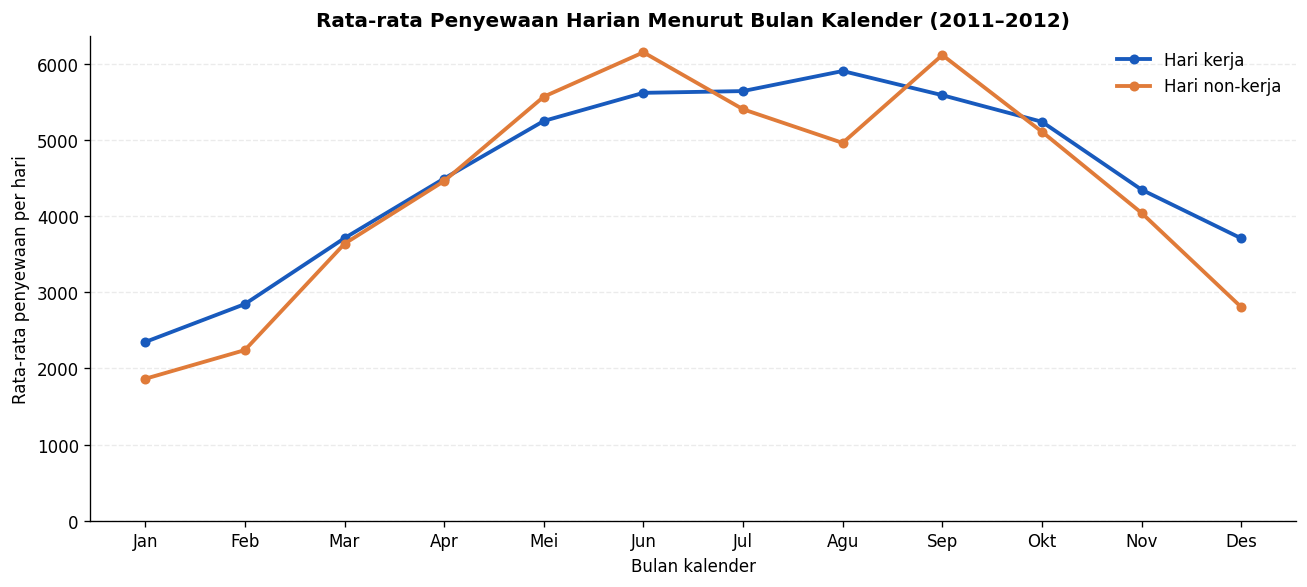

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
for jenis, warna in [('Hari kerja', WARNA_KERJA), ('Hari non-kerja', WARNA_NONKERJA)]:
    data_plot = per_bulan[per_bulan['jenis_hari'].eq(jenis)].sort_values('bulan')
    ax.plot(data_plot['bulan'], data_plot['rata_rata'], marker='o', linewidth=2.3,
            markersize=5, color=warna, label=jenis)
ax.set(title='Rata-rata Penyewaan Harian Menurut Bulan Kalender (2011–2012)',
       xlabel='Bulan kalender', ylabel='Rata-rata penyewaan per hari')
ax.set_xticks(range(1, 13), NAMA_BULAN)
ax.set_ylim(bottom=0)
ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Pertanyaan 2: Puncak rata-rata penyewaan per jam pada jenis hari yang berbeda

Plot di bawah menunjukkan **rata-rata penyewaan setiap jam** setelah melengkapi slot 0; garis menggunakan skala yang sama sehingga perbandingan adil. **17.00** berarti interval jam 17.00–17.59; bukan jumlah pengguna unik.

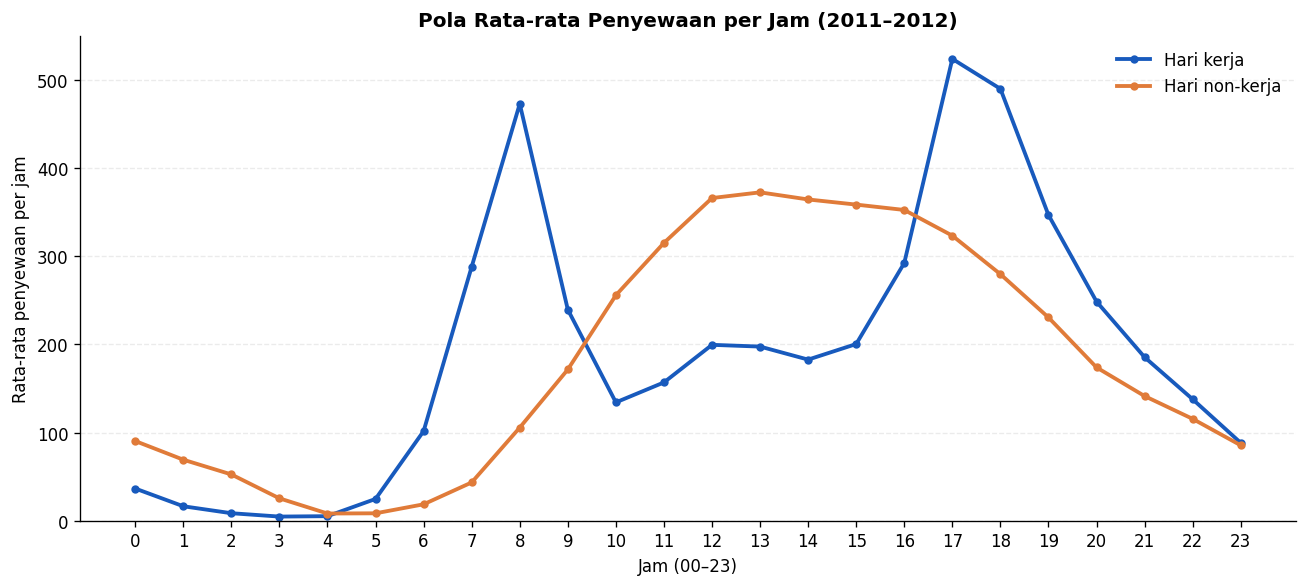

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
for jenis, warna in [('Hari kerja', WARNA_KERJA), ('Hari non-kerja', WARNA_NONKERJA)]:
    data_plot = per_jam[per_jam['jenis_hari'].eq(jenis)].sort_values('hr')
    ax.plot(data_plot['hr'], data_plot['rata_rata'], marker='o', linewidth=2.3,
            markersize=4, color=warna, label=jenis)
ax.set(title='Pola Rata-rata Penyewaan per Jam (2011–2012)',
       xlabel='Jam (00–23)', ylabel='Rata-rata penyewaan per jam')
ax.set_xticks(range(24))
ax.set_ylim(bottom=0)
ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

**Insight Visualization & Explanatory Analysis:** Pada visualisasi pertama, jenis hari yang memiliki rata-rata lebih tinggi **berubah tergantung bulan**; Agustus menunjukkan selisih terbesar yang berpihak pada hari kerja, sedangkan Mei, Juni, dan September memperlihatkan rata-rata hari non-kerja lebih tinggi. Visualisasi kedua menunjukkan dua profil yang berbeda: **lonjakan jam pergi/pulang kerja** di hari kerja (khususnya 08.00 dan 17.00–18.00), dan **puncak tengah hari** pada hari non-kerja (12.00–14.00). Insight ditarik dari agregasi, bukan dari asumsi penyebab.

## Analisis Lanjutan: Segmentasi Tingkat Permintaan (*Binning*)

**Tujuan:** Mengelompokkan tingkat permintaan setiap slot jam menjadi **Rendah, Sedang, Tinggi** secara transparan, sehingga pengelola dapat membandingkan **proporsi jam berpermintaan tinggi** pada setiap jam dan jenis hari. Metode ini **bukan machine learning**. Ambang ditetapkan dari **persentil ke-33,3 dan ke-66,7** seluruh slot pada periode penuh, lalu dipertahankan untuk semua visualisasi/filter tahun agar kelompok bisa dibandingkan secara konsisten. Binning bersifat relatif terhadap dataset historis, **bukan standar kapasitas operasional**.

Ambang kelompok: Rendah ≤ 68; Sedang 69–223; Tinggi > 223 penyewaan/jam.
Komposisi tingkat permintaan:


tingkat_permintaan
Rendah    5859
Sedang    5845
Tinggi    5840
Name: count, dtype: int64

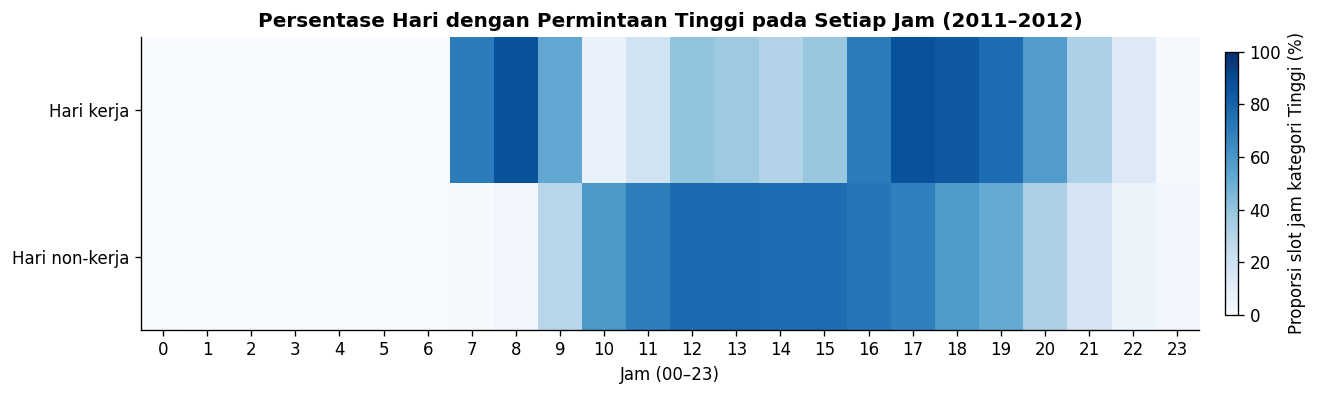

File dashboard disimpan: /mnt/data/submission_dicoding_bike_sharing/dashboard/main_data.csv


In [8]:
ambang_rendah = int(hourly_full['cnt'].quantile(1 / 3))
ambang_tinggi = int(hourly_full['cnt'].quantile(2 / 3))
assert ambang_tinggi > ambang_rendah
hourly_full['tingkat_permintaan'] = pd.cut(
    hourly_full['cnt'], bins=[-1, ambang_rendah, ambang_tinggi, np.inf],
    labels=['Rendah', 'Sedang', 'Tinggi'], include_lowest=True
)
hourly_full['jam_permintaan_tinggi'] = hourly_full['tingkat_permintaan'].eq('Tinggi')

proporsi_tinggi = (hourly_full.groupby(['jenis_hari', 'hr'], observed=True)['jam_permintaan_tinggi']
                   .mean().mul(100).unstack('hr').reindex(urut_jenis_hari))
print(f'Ambang kelompok: Rendah ≤ {ambang_rendah}; Sedang {ambang_rendah+1}–{ambang_tinggi}; Tinggi > {ambang_tinggi} penyewaan/jam.')
print('Komposisi tingkat permintaan:')
display(hourly_full['tingkat_permintaan'].value_counts(dropna=False))

fig, ax = plt.subplots(figsize=(12, 3.4))
im = ax.imshow(proporsi_tinggi.to_numpy(), cmap='Blues', aspect='auto', vmin=0, vmax=100)
ax.set(xticks=range(24), xticklabels=range(24), yticks=[0, 1],
       yticklabels=urut_jenis_hari, xlabel='Jam (00–23)',
       title='Persentase Hari dengan Permintaan Tinggi pada Setiap Jam (2011–2012)')
fig.colorbar(im, ax=ax, shrink=0.9, pad=0.02, label='Proporsi slot jam kategori Tinggi (%)')
fig.tight_layout()
plt.show()

# Menyiapkan satu sumber data yang langsung dibaca dashboard Streamlit.
main_data = hourly_full[['dteday', 'hr', 'cnt', 'casual', 'registered', 'workingday',
                         'jenis_hari', 'tahun', 'bulan', 'tingkat_permintaan']].copy()
main_data['tingkat_permintaan'] = main_data['tingkat_permintaan'].astype(str)
Path('dashboard').mkdir(parents=True, exist_ok=True)
main_data.to_csv('dashboard/main_data.csv', index=False, date_format='%Y-%m-%d')
print('File dashboard disimpan:', Path('dashboard/main_data.csv').resolve())

**Insight Analisis Lanjutan:** Binning menunjukkan pada jam dan jenis hari mana proporsi slot berkategori **Tinggi** paling sering muncul, sehingga melengkapi informasi **rata-rata** pada grafik sebelumnya. Grafik ini menunjukkan **frekuensi relatif** kategori Tinggi, bukan peluang untuk tahun mendatang. Ambang hanya berlaku untuk distribusi historis dataset ini dan tidak langsung boleh dianggap target stok sepeda.

## Conclusion & Recommendation

**Kesimpulan pertanyaan 1:** Selama 1 Januari 2011–31 Desember 2012, rerata penyewaan adalah sekitar **4.584,82 per hari kerja** dan **4.330,17 per hari non-kerja**. Namun pola antarbulan tidak seragam: selisih absolut terbesar terjadi di **Agustus**, ketika rata-rata pada hari kerja **lebih tinggi sekitar 944,80 penyewaan per hari** daripada hari non-kerja. Karena data menggabungkan dua tahun, nilai ini menggambarkan pola gabungan periode 2011–2012, bukan gambaran Agustus tiap tahun secara identik.

**Kesimpulan pertanyaan 2:** Pada **hari kerja**, rerata penyewaan per jam tertinggi terjadi **17.00–17.59** (sekitar **525,29 penyewaan/jam**), dengan lonjakan lain pada **08.00**. Pada **hari non-kerja**, rata-rata tertinggi terjadi **13.00–13.59** (sekitar **372,73 penyewaan/jam**), dengan permintaan tinggi relatif tersebar pada tengah hari. Profil tersebut mendukung penjadwalan penempatan sepeda yang berbeda menurut jenis hari.

**Rekomendasi Action Item:**

1. **Prioritaskan peninjauan stok dan redistribusi sebelum jam 08.00 serta menjelang 17.00 pada hari kerja**; lakukan pemantauan dan penempatan bertahap menjelang 12.00–14.00 pada hari non-kerja. Uji di lapangan terlebih dahulu, karena dataset tidak memuat lokasi stasiun, persediaan riil, dan jumlah sepeda tersedia.
2. **Evaluasi kapasitas menurut bulan dan jenis hari**, khususnya pada **Agustus** ketika selisih rata-rata harian paling besar. Gunakan hasil ini sebagai dasar pemantauan, bukan keputusan otomatis menaikkan armada tanpa melihat kapasitas/stasiun.
3. **Pantau proporsi jam berkategori Tinggi** dalam laporan operasional sebagai sinyal waktu yang perlu dicek lebih awal; lakukan penyesuaian ambang bila menggunakan data terbaru.

**Keterbatasan:** Data hanya 2011–2012 dan berasal dari satu layanan di Washington, D.C.; tidak ada informasi stok sepeda, posisi stasiun, pelanggan unik, atau biaya operasional. Hasil berupa perbandingan deskriptif, **bukan bukti kausal** dan tidak boleh digeneralisasi langsung ke periode atau kota lain. Asumsi slot tak tercatat = 0 berlaku karena total per jam cocok persis dengan data harian; data cuaca kosong tidak direkayasa menjadi 0.